In [1]:
import os
from pathlib import Path
from time import perf_counter

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

In [2]:
# =========================================================
# Configuration
# =========================================================

ROOT_DIR = Path('/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUSI/dataset')
SAVE_DIR = Path('/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUSI/')

IMAGE_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 100
LR = 1e-4

In [3]:
# =========================================================
# Utils: Torch Dice / IoU (works with logits)
# =========================================================

@torch.no_grad()
def dice_from_logits(logits: torch.Tensor, targets: torch.Tensor, threshold: float = 0.5, eps: float = 1e-6) -> torch.Tensor:
    """
    logits:  [B, 1, H, W] (raw, no sigmoid)
    targets: [B, 1, H, W] float {0,1}
    """
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    dims = (1, 2, 3)
    intersection = (preds * targets).sum(dims)
    denom = preds.sum(dims) + targets.sum(dims)
    dice = (2.0 * intersection + eps) / (denom + eps)
    return dice.mean()

@torch.no_grad()
def iou_from_logits(logits: torch.Tensor, targets: torch.Tensor, threshold: float = 0.5, eps: float = 1e-6) -> torch.Tensor:
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    dims = (1, 2, 3)
    intersection = (preds * targets).sum(dims)
    union = preds.sum(dims) + targets.sum(dims) - intersection
    iou = (intersection + eps) / (union + eps)
    return iou.mean()

@torch.no_grad()
def evaluate_model(model: nn.Module, loader: DataLoader, device: str = "cuda") -> dict:
    model.eval()
    criterion = nn.BCEWithLogitsLoss()

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    n = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device).float().unsqueeze(1)  # [B,1,H,W]

        logits = model(images)  # [B,1,h,w]
        logits = F.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)

        loss = criterion(logits, masks).item()
        d = dice_from_logits(logits, masks).item()
        j = iou_from_logits(logits, masks).item()

        total_loss += loss
        total_dice += d
        total_iou += j
        n += 1

    if n == 0:
        return {"loss": 0.0, "dice": 0.0, "iou": 0.0}

    return {"loss": total_loss / n, "dice": total_dice / n, "iou": total_iou / n}

In [4]:
# =========================================================
# Model: plain U-Net
# =========================================================

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, features=(64, 128, 256, 512)):
        super().__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Down part of UNet
        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        # Up part of UNet
        for feature in reversed(features):
            self.ups.append(nn.ConvTranspose2d(feature * 2, feature, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(feature * 2, feature))

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip = skip_connections[idx // 2]

            if x.shape[2:] != skip.shape[2:]:
                x = TF.resize(x, size=skip.shape[2:])

            x = torch.cat((skip, x), dim=1)
            x = self.ups[idx + 1](x)

        return self.final_conv(x)

In [5]:
# =========================================================
# Dataset
# =========================================================
# Expects a layout like:
#   ROOT_DIR/{split}/images/xxx.png
#   ROOT_DIR/{split}/masks/xxx_mask.png
# Images/masks are loaded with cv2.IMREAD_ANYDEPTH and min-max normalized,
# matching the original BUSI preprocessing.

class BinarySegmentationDataset(Dataset):
    def __init__(self, images_dir, masks_dir, img_size=256):
        self.images_dir = Path(images_dir)
        self.masks_dir = Path(masks_dir)
        self.img_size = img_size
        self.mask_paths = sorted(self.masks_dir.glob("*.png"))

    def __len__(self):
        return len(self.mask_paths)

    def __getitem__(self, idx):
        mask_path = self.mask_paths[idx]
        mask = cv2.imread(str(mask_path), cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())
        mask = (mask > 0).astype(np.float32)
        mask = cv2.resize(mask, (self.img_size, self.img_size), interpolation=cv2.INTER_AREA)
        mask = torch.from_numpy(mask)

        img_path = Path(str(mask_path).replace("_mask.png", ".png").replace(str(self.masks_dir), str(self.images_dir)))
        image = cv2.imread(str(img_path), cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min())
        image = image.astype(np.float32)
        image = cv2.resize(image, (self.img_size, self.img_size), interpolation=cv2.INTER_AREA)
        image = np.expand_dims(image, axis=0)  # [1,H,W]
        image = torch.from_numpy(image)

        return image, mask

In [6]:
# =========================================================
# Training Function
# =========================================================

def train_model(model, train_loader, val_loader, epochs=100, lr=1e-4, device="cuda", save_dir="checkpoints", ckpt_name="best_model.pth"):
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.AdamW(model.parameters(), lr=lr)
    scheduler = StepLR(optimizer, step_size=100, gamma=0.83)
    scaler = torch.amp.GradScaler("cuda")

    best_dice = -1.0

    train_loss_hist, val_loss_hist, val_dice_hist = [], [], []

    for epoch in range(epochs):
        start_time = perf_counter()
        model.train()
        train_loss = 0.0

        for images, masks in train_loader:
            images = images.to(device)
            masks = masks.to(device).float().unsqueeze(1)  # [B,1,H,W]

            optimizer.zero_grad()
            with torch.autocast(device_type="cuda"):
                logits = model(images)
                logits = F.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
                loss = criterion(logits, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()

        train_loss /= max(1, len(train_loader))
        scheduler.step()

        # Validation
        val_stats = evaluate_model(model, val_loader, device=device)
        val_loss = val_stats["loss"]
        val_dice = val_stats["dice"]
        val_iou = val_stats["iou"]

        train_loss_hist.append(train_loss)
        val_loss_hist.append(val_loss)
        val_dice_hist.append(val_dice)

        print(
            f"Epoch {epoch+1:>3}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f}"
        )

        # Save best model by Dice
        if val_dice > best_dice:
            best_dice = val_dice
            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "val_loss": val_loss,
                    "val_dice": val_dice,
                    "val_iou": val_iou,
                },
                save_dir / ckpt_name,
            )
            print(f"✓ Saved best model (Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f})")

        end_time = perf_counter()
        print(f"Time taken: {end_time - start_time:.2f} seconds.\n")

    history = {"train_loss": train_loss_hist, "val_loss": val_loss_hist, "val_dice": val_dice_hist}
    return model, history

In [7]:
# =========================================================
# Inference Function
# =========================================================

@torch.no_grad()
def predict(model, image_path, device="cuda", threshold=0.5, img_size=256):
    model.eval()
    model = model.to(device)

    image_path = str(image_path)
    img = cv2.imread(image_path, cv2.IMREAD_ANYDEPTH)
    img = (img - img.min()) / (img.max() - img.min())
    img = img.astype(np.float32)

    orig_h, orig_w = img.shape[:2]
    img_resized = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_LINEAR)

    x = torch.from_numpy(img_resized).unsqueeze(0).unsqueeze(0)
    x = x.to(device)

    logits = model(x)  # [1,1,h,w]
    probs = torch.sigmoid(logits)
    pred = (probs > threshold).float().squeeze(0).squeeze(0).cpu().numpy()

    pred_resized = cv2.resize(pred, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
    prob_resized = cv2.resize(probs.squeeze(0).squeeze(0).cpu().numpy(), (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)

    return pred_resized, prob_resized

In [8]:
# =========================================================
# Visualization Function
# =========================================================

def visualize_prediction(image_path, pred_mask, output_path="output.png"):
    image_path = str(image_path)
    output_path = str(output_path)

    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if img is None:
        raise RuntimeError(f"cv2.imread failed for image: {image_path}")

    mask_color = np.zeros_like(img)
    mask_color[pred_mask == 1] = [0, 255, 0]  # green overlay in BGR

    overlay = cv2.addWeighted(img, 0.7, mask_color, 0.3, 0)
    cv2.imwrite(output_path, overlay)
    print(f"✓ Saved visualization to {output_path}")

In [9]:
# =========================================================
# Main
# =========================================================

if __name__ == "__main__":
    torch.manual_seed(42)
    torch.backends.cudnn.benchmark = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {DEVICE}")

    model = UNet(in_channels=1, out_channels=1, features=(64, 128, 256, 512))
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params:,}")

    train_dataset = BinarySegmentationDataset(
        images_dir=ROOT_DIR / "train" / "images",
        masks_dir=ROOT_DIR / "train" / "masks",
        img_size=IMAGE_SIZE,
    )
    val_dataset = BinarySegmentationDataset(
        images_dir=ROOT_DIR / "val" / "images",
        masks_dir=ROOT_DIR / "val" / "masks",
        img_size=IMAGE_SIZE,
    )
    test_dataset = BinarySegmentationDataset(
        images_dir=ROOT_DIR / "test" / "images",
        masks_dir=ROOT_DIR / "test" / "masks",
        img_size=IMAGE_SIZE,
    )

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=(DEVICE == "cuda"))
    val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(DEVICE == "cuda"))
    test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(DEVICE == "cuda"))

    print(f"\nTrain dataset size: {len(train_dataset)}")
    print(f"Train loader batches: {len(train_loader)}\n")
    data_batch, mask_batch = next(iter(train_loader))
    print("data_batch.size=", data_batch.size())

    print(f"\nValidation dataset size: {len(val_dataset)}")
    print(f"Validation loader batches: {len(val_loader)}\n")

    print(f"Test dataset size: {len(test_dataset)}")
    print(f"Test loader batches: {len(test_loader)}\n")

    print("Training started...\n")
    model, history = train_model(
        model,
        train_loader,
        val_loader,
        epochs=EPOCHS,
        lr=LR,
        device=DEVICE,
        save_dir=SAVE_DIR,
        ckpt_name="best_model_unet.pth",
    )

    # Load best model
    ckpt_path = SAVE_DIR / "best_model_unet.pth"
    checkpoint = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"\n✓ Loaded best model from epoch {checkpoint['epoch'] + 1} | Val Dice: {checkpoint['val_dice']:.4f}")

    # Evaluate on test set
    test_stats = evaluate_model(model.to(DEVICE), test_loader, device=DEVICE)
    print(f"TEST | Loss: {test_stats['loss']:.4f} | Dice: {test_stats['dice']:.4f} | IoU: {test_stats['iou']:.4f}")
    print("Finished.")

    # Example inference on first test image (robust to extensions)
    #sample_img_path = ...
    #pred_mask, prob_map = predict(model, sample_img_path, device=DEVICE, threshold=0.5, img_size=IMAGE_SIZE)
    #out_vis = ROOT_DIR / "segmentation_output.png"
    #visualize_prediction(sample_img_path, pred_mask, out_vis)

Using device: cuda
Total parameters: 31,036,481

Train dataset size: 545
Train loader batches: 69



/tmp/ipykernel_1002308/2051166531.py:23: RuntimeWarning: invalid value encountered in divide
  mask = (mask - mask.min()) / (mask.max() - mask.min())


data_batch.size= torch.Size([8, 1, 256, 256])

Validation dataset size: 117
Validation loader batches: 15

Test dataset size: 118
Test loader batches: 15

Training started...

Epoch   1/100 | Train Loss: 0.4925 | Val Loss: 0.4217 | Val Dice: 0.2698 | Val IoU: 0.2477
✓ Saved best model (Val Dice: 0.2698 | Val IoU: 0.2477)
Time taken: 47.26 seconds.

Epoch   2/100 | Train Loss: 0.3873 | Val Loss: 0.4283 | Val Dice: 0.3063 | Val IoU: 0.2329
✓ Saved best model (Val Dice: 0.3063 | Val IoU: 0.2329)
Time taken: 14.82 seconds.

Epoch   3/100 | Train Loss: 0.3448 | Val Loss: 0.3406 | Val Dice: 0.4286 | Val IoU: 0.3722
✓ Saved best model (Val Dice: 0.4286 | Val IoU: 0.3722)
Time taken: 14.96 seconds.

Epoch   4/100 | Train Loss: 0.3216 | Val Loss: 0.3394 | Val Dice: 0.3632 | Val IoU: 0.2679
Time taken: 11.94 seconds.

Epoch   5/100 | Train Loss: 0.2922 | Val Loss: 0.2938 | Val Dice: 0.4373 | Val IoU: 0.3535
✓ Saved best model (Val Dice: 0.4373 | Val IoU: 0.3535)
Time taken: 14.85 seconds.

Epoch

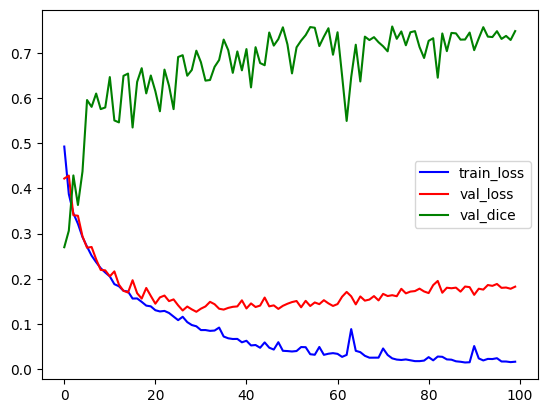

In [10]:
plt.plot(history["train_loss"], color="blue", label="train_loss")
plt.plot(history["val_loss"], color="red", label="val_loss")
plt.plot(history["val_dice"], color="green", label="val_dice")
plt.legend()
plt.show()